In [ ]:
%pip install openplay

In [48]:
import openplay as op
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

all_shots = []
op.competitions()
# Collect data from 2016/17 to 2025/26 season 
for season_year in range(16,26):
    season = f"{str(season_year)}{str(season_year + 1)}"
    shots = op.shots("ger", season)
    print(f"Collected {len(shots)} shots")
    all_shots.append(shots)
    

gerShots = pd.concat(all_shots, ignore_index=True)

print(f"Total shots: {len(gerShots)}")

gerShots.to_csv("ger_shots_2016_2025.csv", index=False)

Collected 7651 shots
Collected 7760 shots
Collected 8273 shots
Collected 8152 shots
Collected 7602 shots
Collected 7961 shots


C:\Users\Jordan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\openplay\api.py:167: CoverageWarning: 2 played match(es) in this selection have no event data; see known_gaps()
  coverage_report(comp, season, warn=True)


Collected 7773 shots
Collected 8522 shots


C:\Users\Jordan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\openplay\api.py:167: CoverageWarning: 2 match(es) in this selection have known data issues; see data_issues()
  coverage_report(comp, season, warn=True)


Collected 7959 shots
Collected 8130 shots
Total shots: 79783


# Question 1: How does shot location affect the probability of scoring?

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

shots = pd.read_csv("ger_shots_2016_2025.csv")

# Exclude own goals
shots = shots[~shots["is_own_goal"]].copy()
shots["is_goal"] = shots["is_goal"].astype(int)

# Divide the field into zones
shots["x_zone"] = pd.cut(shots["x"], bins=np.linspace(0, 100, 11))
shots["y_zone"] = pd.cut(shots["y"], bins=np.linspace(0, 100, 11))

# Calculate stats for each zone
zone_stats = shots.groupby(
    ["x_zone", "y_zone"], observed=True
).agg(
    total_shots = ("is_goal", "count"),
    goals = ("is_goal", "sum"),
    avg_xg = ("xg", "mean")
)

zone_stats["conversion_rate"] = (
    zone_stats["goals"] / zone_stats["total_shots"]
)

print(zone_stats.head(10))
print(zone_stats.tail(10))

                           total_shots  goals  avg_xg  conversion_rate
x_zone       y_zone                                                   
(10.0, 20.0] (0.0, 10.0]             1      0     NaN              0.0
(20.0, 30.0] (30.0, 40.0]            1      0     NaN              0.0
             (40.0, 50.0]            1      0     NaN              0.0
             (60.0, 70.0]            1      0     NaN              0.0
(30.0, 40.0] (0.0, 10.0]             2      0     NaN              0.0
             (10.0, 20.0]            2      0     NaN              0.0
             (20.0, 30.0]            3      0     NaN              0.0
             (30.0, 40.0]            6      0     NaN              0.0
             (40.0, 50.0]            2      0     NaN              0.0
             (50.0, 60.0]            8      0     NaN              0.0
                             total_shots  goals    avg_xg  conversion_rate
x_zone        y_zone                                                     

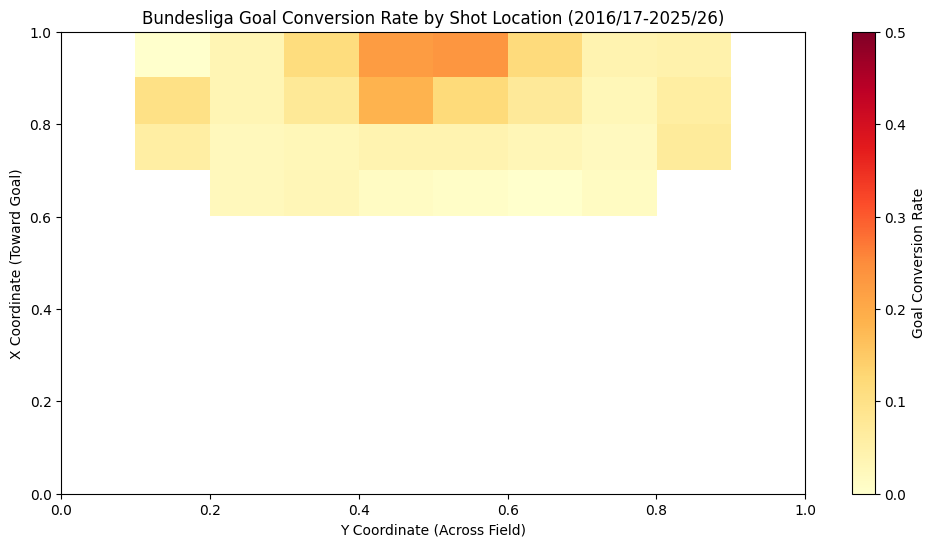

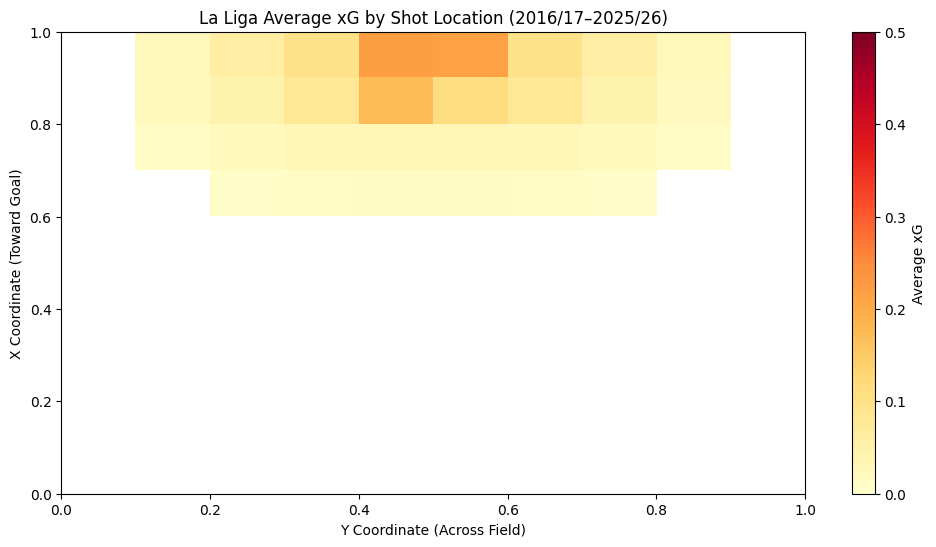

In [47]:
x_zones = shots["x_zone"].cat.categories
y_zones = shots["y_zone"].cat.categories

# Create grids using the correct categories
conversion_grid = zone_stats["conversion_rate"].unstack()
xg_grid = zone_stats["avg_xg"].unstack()
shot_count_grid = zone_stats["total_shots"].unstack()

# Reindex using the original interval categories
conversion_grid = conversion_grid.reindex(index=x_zones, columns=y_zones)
xg_grid = xg_grid.reindex(index=x_zones, columns=y_zones)

# Filter out zones with less than 30 shots
conversion_grid = conversion_grid.where(shot_count_grid >= 30)
xg_grid = xg_grid.where(shot_count_grid >= 30)


# Conversion rate heatmap
plt.figure(figsize=(12, 6))

plt.imshow(
    conversion_grid,
    origin="lower",
    cmap="YlOrRd",
    vmin=0,
    vmax=0.5,
    extent=[0, 1, 0, 1],
    aspect="auto"
)

plt.colorbar(label="Goal Conversion Rate")
plt.xlabel("Y Coordinate (Across Field)")
plt.ylabel("X Coordinate (Toward Goal)")
plt.title("Bundesliga Goal Conversion Rate by Shot Location (2016/17-2025/26)")

plt.show()

# Average xG heatmap
plt.figure(figsize=(12, 6))

plt.imshow(
    xg_grid,
    origin="lower",
    cmap="YlOrRd",
    vmin=0,
    vmax=0.5,
    extent=[0, 1, 0, 1],
    aspect="auto"
)

plt.colorbar(label="Average xG")
plt.xlabel("Y Coordinate (Across Field)")
plt.ylabel("X Coordinate (Toward Goal)")
plt.title("La Liga Average xG by Shot Location (2016/17–2025/26)")

plt.show()

# Question 2: Are teams that create more chances from open play more successful than set piece dependent teams?

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("ger_shots_2016_2025.csv")

# Use the season starting year (1617 -> 2016)
df["season"] = 2000 + df["season"] // 100

print("Total shots:", len(df))
print("Seasons:", sorted(df["season"].unique()))
print("Teams:", df["team_id"].nunique())

display(df.head())

Total shots: 79783
Seasons: [np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Teams: 30


,comp,season,match_id,event_id,event_id_sub,team_event_id,period,minute,second,expanded_minute,...,goal_mouth_z,blocked_x,blocked_y,xg,assist_player_id,assist_player,assist_type,assist_event_type,assist_event_id,xg_model
0,ger,2016,1090788,587691753,0,164,FirstHalf,6,49,6,...,NaN,88.1,46.9,0.157230,5570.0,Philipp Lahm,pass,Pass,1.509344e+09,openplay_xg_v1
1,ger,2016,1090788,121458567,0,184,FirstHalf,8,14,8,...,27.8,NaN,NaN,0.019600,NaN,NaN,NaN,NaN,NaN,openplay_xg_v1
2,ger,2016,1090788,237906373,0,108,FirstHalf,9,27,9,...,NaN,75.6,57.4,0.026100,NaN,NaN,NaN,NaN,NaN,openplay_xg_v1
3,ger,2016,1090788,517206772,0,201,FirstHalf,10,36,10,...,15.8,98.2,46.2,0.203661,5570.0,Philipp Lahm,pass,Pass,1.323917e+09,openplay_xg_v1
4,ger,2016,1090788,1493131651,0,203,FirstHalf,10,41,10,...,NaN,91.5,52.5,0.152947,NaN,NaN,NaN,NaN,NaN,openplay_xg_v1


In [50]:
# Classify shot situations (penalties count as set pieces)
df["shot_category"] = np.where(
    df["is_set_piece"] | df["is_penalty"], "Set Piece", "Open Play"
)

# Goal and own-goal flags are already in the OpenPlay CSV
df["is_goal"] = df["is_goal"].astype(int)
df["is_own_goal"] = df["is_own_goal"].astype(int)

# Exclude own goals
shots = df[df["is_own_goal"] == 0].copy()

print(shots["shot_category"].value_counts())

shot_category
Open Play    57715
Set Piece    21835
Name: count, dtype: int64


In [51]:
category_stats = (
    shots.groupby("shot_category")
    .agg(
        Shots=("event_id", "count"),
        Goals=("is_goal", "sum"),
        Total_xG=("xg", "sum"),
        Average_xG=("xg", "mean")
    )
    .reset_index()
)

category_stats["Conversion_Rate"] = (
    category_stats["Goals"] / category_stats["Shots"] * 100
)

category_stats["Average_xG"] *= 100

display(category_stats.round(2))

,shot_category,Shots,Goals,Total_xG,Average_xG,Conversion_Rate
0,Open Play,57715,6681,5961.64,10.35,11.58
1,Set Piece,21835,2552,2759.65,12.65,11.69


<Figure size 900x500 with 0 Axes>

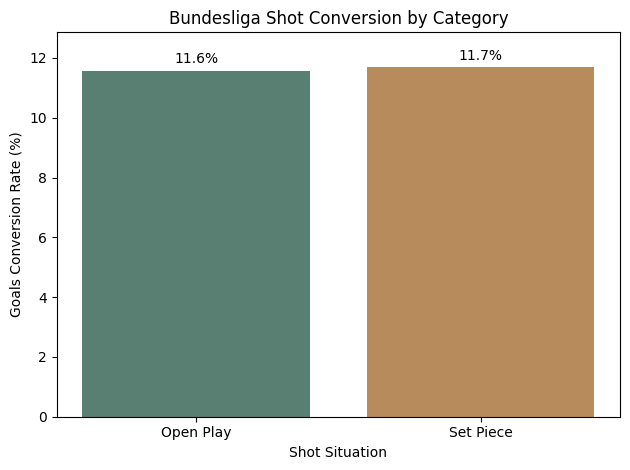

In [67]:
plt.figure(figsize=(9, 5))
colors = ['#587f72', '#b78b5b']

fig, ax = plt.subplots()
bars = ax.bar(
    category_stats["shot_category"],
    category_stats["Conversion_Rate"],
    color=colors
)
ax.bar_label(bars, padding=3, fmt='%.1f%%')
ax.set_ylim(0, max(category_stats["Conversion_Rate"]) * 1.10)

plt.title("Bundesliga Shot Conversion by Category")
plt.xlabel("Shot Situation")
plt.ylabel("Goals Conversion Rate (%)")


plt.tight_layout()
plt.show()


In [68]:
# Focus on the two main categories
main_shots = shots[
    shots["shot_category"].isin(["Open Play", "Set Piece"])
].copy()

team_stats = (
    main_shots.groupby(
        ["season", "team_id", "shot_category"]
    )
    .agg(
        Shots=("event_id", "count"),
        Goals=("is_goal", "sum"),
        xG=("xg", "sum")
    )
    .unstack(fill_value=0)
)

# Flatten the column names
team_stats.columns = [
    f"{metric}_{category.replace(' ', '_')}"
    for metric, category in team_stats.columns
]

team_stats = team_stats.reset_index()

for category in ["Open_Play", "Set_Piece"]:
    for metric in ["Shots", "Goals", "xG"]:
        column = f"{metric}_{category}"
        if column not in team_stats.columns:
            team_stats[column] = 0

team_stats["Total_Shots"] = (
    team_stats["Shots_Open_Play"] +
    team_stats["Shots_Set_Piece"]
)

team_stats["Set_Piece_Share"] = (
    team_stats["Shots_Set_Piece"] /
    team_stats["Total_Shots"] * 100
)

team_stats["Open_Play_Share"] = (
    team_stats["Shots_Open_Play"] /
    team_stats["Total_Shots"] * 100
)

team_stats["Set_Piece_Conversion"] = (
    team_stats["Goals_Set_Piece"] /
    team_stats["Shots_Set_Piece"].replace(0, np.nan) * 100
)

team_stats["Open_Play_Conversion"] = (
    team_stats["Goals_Open_Play"] /
    team_stats["Shots_Open_Play"].replace(0, np.nan) * 100
)

display(team_stats.head())

,season,team_id,Shots_Open_Play,Shots_Set_Piece,Goals_Open_Play,Goals_Set_Piece,xG_Open_Play,xG_Set_Piece,Total_Shots,Set_Piece_Share,Open_Play_Share,Set_Piece_Conversion,Open_Play_Conversion
0,2016,33,305,127,19,13,30.871998,14.241381,432,29.398148,70.601852,10.236220,6.229508
1,2016,36,318,128,38,15,32.086717,17.751777,446,28.699552,71.300448,11.718750,11.949686
2,2016,37,451,171,67,21,52.391608,17.261905,622,27.491961,72.508039,12.280702,14.855876
3,2016,38,245,115,26,6,22.693616,9.501069,360,31.944444,68.055556,5.217391,10.612245
4,2016,39,306,137,37,8,31.475355,14.503465,443,30.925508,69.074492,5.839416,12.091503


In [69]:
# Find two teams per match
match_teams = df[["match_id", "season", "team_id"]].drop_duplicates()
match_teams = match_teams[
    match_teams.groupby(["season", "match_id"])["team_id"].transform("size").eq(2)
].copy()

# Count normal goals and own goals per team
normal_goals = (
    df[(df["is_goal"] == 1) & (df["is_own_goal"] == 0)]
    .groupby(["season", "match_id", "team_id"])
    .size().reset_index(name="normal_goals")
)
own_goals = (
    df[df["is_own_goal"] == 1]
    .groupby(["season", "match_id", "team_id"])
    .size().reset_index(name="own_goals_by")
)

scores = (match_teams
    .merge(normal_goals, on=["season", "match_id", "team_id"], how="left")
    .merge(own_goals, on=["season", "match_id", "team_id"], how="left")
)
scores[["normal_goals", "own_goals_by"]] = scores[["normal_goals", "own_goals_by"]].fillna(0)

# Award own goals to the other team
match_goals = scores.groupby(["season", "match_id"])[["normal_goals", "own_goals_by"]].transform("sum")
scores["goals_for"] = scores["normal_goals"] + match_goals["own_goals_by"] - scores["own_goals_by"]
scores["goals_against"] = match_goals["normal_goals"] + match_goals["own_goals_by"] - scores["goals_for"]

# Calculate match points
scores["Points"] = np.select(
    [scores["goals_for"] > scores["goals_against"],
     scores["goals_for"] == scores["goals_against"]],
    [3, 1], default=0
)

# Calculate points earned by each team each season
team_points = (
    scores.groupby(["season", "team_id"])
    .agg(Matches=("match_id", "nunique"), Points=("Points", "sum"))
    .reset_index()
)
team_points["Points_Per_Game"] = team_points["Points"] / team_points["Matches"]

# Combine team performance with shot statistics
team_stats = team_stats.merge(team_points, on=["season", "team_id"], how="inner")

display(team_stats.head())
print("Note: points are reconstructed from shot event goals, not official standings.")

,season,team_id,Shots_Open_Play,Shots_Set_Piece,Goals_Open_Play,Goals_Set_Piece,xG_Open_Play,xG_Set_Piece,Total_Shots,Set_Piece_Share,Open_Play_Share,Set_Piece_Conversion,Open_Play_Conversion,Matches,Points,Points_Per_Game
0,2016,33,305,127,19,13,30.871998,14.241381,432,29.398148,70.601852,10.236220,6.229508,34,37,1.088235
1,2016,36,318,128,38,15,32.086717,17.751777,446,28.699552,71.300448,11.718750,11.949686,34,41,1.205882
2,2016,37,451,171,67,21,52.391608,17.261905,622,27.491961,72.508039,12.280702,14.855876,34,82,2.411765
3,2016,38,245,115,26,6,22.693616,9.501069,360,31.944444,68.055556,5.217391,10.612245,34,38,1.117647
4,2016,39,306,137,37,8,31.475355,14.503465,443,30.925508,69.074492,5.839416,12.091503,34,43,1.264706


Note: points are reconstructed from shot event goals, not official standings.


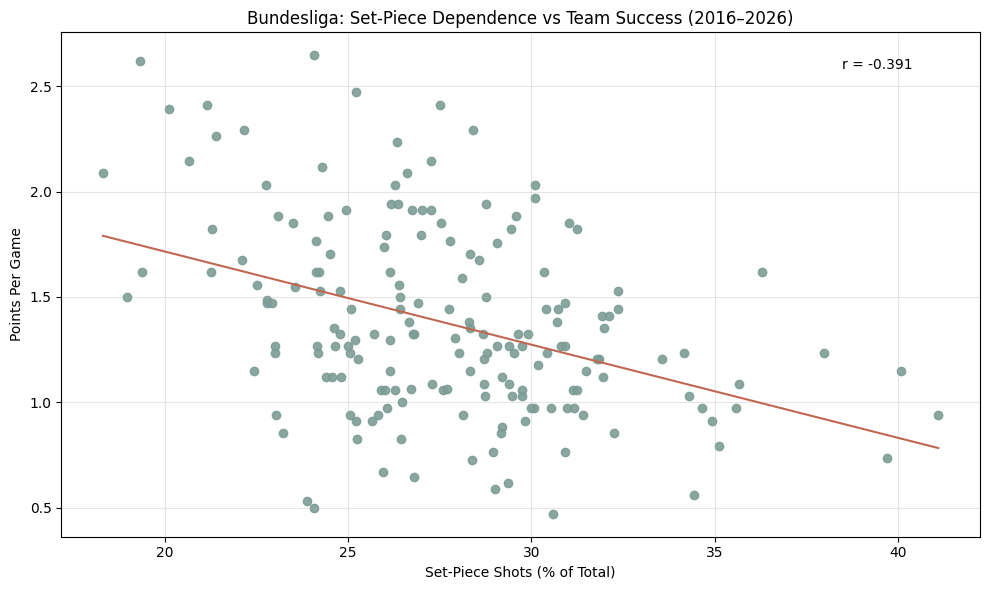

Correlation: -0.391


In [ ]:
plt.figure(figsize=(10, 6))
colors = ['#7c9c95']

plt.scatter(
    team_stats["Set_Piece_Share"],
    team_stats["Points_Per_Game"],
    alpha=0.90,
    color=colors
)

# Calculate correlation
correlation = team_stats[
    ["Set_Piece_Share", "Points_Per_Game"]
].corr().iloc[0, 1]

# Add trend line
x = team_stats["Set_Piece_Share"]
y = team_stats["Points_Per_Game"]

slope, intercept = np.polyfit(x, y, 1)

x_line = np.linspace(x.min(), x.max(), 100)
plt.plot(x_line, slope * x_line + intercept, color="#c06752")

plt.title("Bundesliga: Set-Piece Dependence vs Team Success (2016–2026)")
plt.xlabel("Set-Piece Shots (% of Total)")
plt.ylabel("Points Per Game")

plt.text(
    0.85, 0.95,
    f"r = {correlation:.3f}",
    transform=plt.gca().transAxes,
    va="top"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Correlation:", round(correlation, 3))

# Question 3: Which teams have the largest differences in actual points and expected points?

In [14]:
matchdf = pd.read_csv("ger_shots_2016_2025.csv");

# Preprocessing to help parse 'Own Goals'
matchdf["is_goal"] = (matchdf["result"] == "Goal").astype(int)
matchdf["is_own_goal"] = (matchdf["result"] == "Own Goal").astype(int)
matchdf["xg_valid"] = matchdf["xg"].where(matchdf["result"] != "Own Goal", 0)

# One Row per Team per Match
teamGames = (matchdf.groupby(["season", "match_id", "team"], as_index=False)
            .agg(xg_for=("xg_valid", "sum"),
                 goals_scored=("is_goal", "sum"),
                 own_goals_by=("is_own_goal", "sum")))

# Gather stats from single games
singleGame = teamGames.groupby(["season", "match_id"])
# Expected goals by team in season
xgTotal = singleGame["xg_for"].transform("sum")
# Own goals by team in season
ownGoalsTotal = singleGame["own_goals_by"].transform("sum")
# Goals scored by team in season
goalsTotal = singleGame["goals_scored"].transform("sum") + ownGoalsTotal

teamGames["goals_for"] = teamGames["goals_scored"] + (ownGoalsTotal - teamGames["own_goals_by"])
teamGames["goals_against"] = goalsTotal - teamGames["goals_for"]
teamGames["xg_against"] = xgTotal - teamGames["xg_for"]

def summarizeShotData(df, by):
     out = (df.groupby(by, as_index=False)
               .agg(matches=("match_id", "count"),
               goals_for=("goals_for", "sum"), xg_for=("xg_for", "sum"),
               goals_against=("goals_against", "sum"), xg_against=("xg_against", "sum")))
     # How team scored vs expectation
     # Main component of research question
     out["gf_diff"] = out["goals_for"] - out["xg_for"]
     # How team fared defending vs expectation
     out["ga_diff"] = out["goals_against"] - out["xg_against"]
     # How team was expected to score against opponent
     out["xg_diff"] = out["xg_for"] - out["xg_against"]
     return out

# Each team, per season
seasonTable = summarizeShotData(teamGames, ["season", "team"])
# Each team over all seasons
overallTable = summarizeShotData(teamGames, ["team"])

print("Biggest single season finishing overperformers (goals above xG):")
print(seasonTable.sort_values("gf_diff", ascending=False).head(10).round(1))

print("\nBiggest single season finishing underperformers (goals below xG):")
print(seasonTable.sort_values("gf_diff").head(10).round(1))

print("\nOverall, largest increase from xG to goals")
orderOverall = overallTable["gf_diff"].sort_values(ascending=False).index
print(overallTable.loc[orderOverall].head(10).round(1))


Biggest single season finishing overperformers (goals above xG):
     season               team  matches  goals_for  xg_for  goals_against  \
56     1920  Borussia Dortmund       34         87    52.1             38   
163    2526             Bayern       34        119    87.2             39   
74     2021             Bayern       34         98    70.9             45   
38     1819  Borussia Dortmund       34         80    55.7             45   
94     2122  Borussia Dortmund       34         83    59.8             54   
19     1718             Bayern       34         93    70.0             27   
145    2425             Bayern       34         96    73.5             35   
55     1920             Bayern       34         98    75.7             34   
109    2223             Bayern       34         90    68.0             40   
16     1617      Werder Bremen       34         62    42.3             63   

     xg_against  gf_diff  ga_diff  xg_diff  
56         36.8     34.9      1.2     15.3

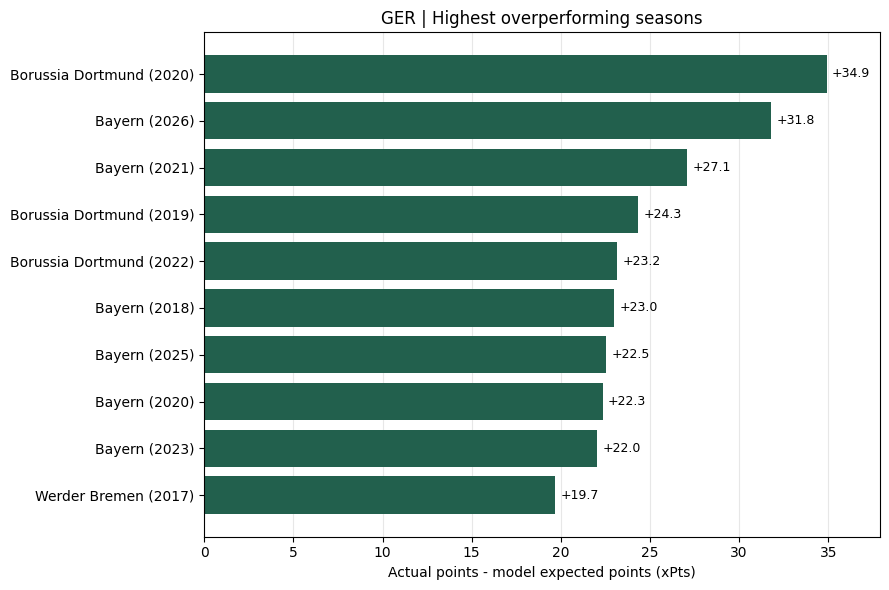

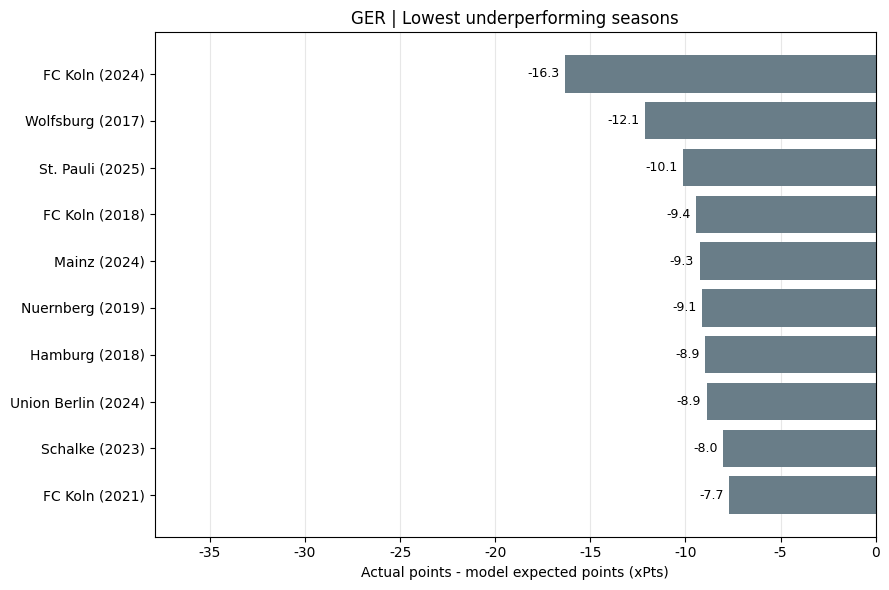

In [43]:
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

season_table = seasonTable[seasonTable["matches"] >= 34].copy()
season_table["season_id"] = "20" + season_table["season"].astype(str).str[2:4]
season_table["label"] = season_table["team"] + " (" + season_table["season_id"] + ")"
season_table["abs_diff"] = season_table["gf_diff"].abs()

n = 10
over_color, under_color = "#22604d", "#697d88ff"

# Largest gains (goals above xG) and largest drops (goals below xG)
top_gains = season_table.nlargest(n, "gf_diff").sort_values("abs_diff")
top_drops = season_table.nsmallest(n, "gf_diff").sort_values("abs_diff")

# Shared axis range so the two charts are comparable
xmax = max(top_gains["abs_diff"].max(), top_drops["abs_diff"].max()) + 3

def draw_chart(data, color, title, xlabel, right_justified=False):
    fig, ax = plt.subplots(figsize=(9, 6))
    bars = ax.barh(data["label"], data["abs_diff"], color=color, zorder=2)
    for i, (bar_len, signed) in enumerate(zip(data["abs_diff"], data["gf_diff"])):
        ax.annotate(f"{signed:+.1f}", xy=(bar_len, i),
                    xytext=(-4 if right_justified else 4, 0), textcoords="offset points",
                    ha="right" if right_justified else "left", va="center", fontsize=9)

    if right_justified:
        ax.set_xlim(xmax, 0)
        ax.xaxis.set_major_formatter(lambda x, pos: f"{-x:g}" if x != 0 else "0")
    else:
        ax.set_xlim(0, xmax)        # zero on the left, bars grow rightward

    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.xaxis.set_major_locator(MultipleLocator(5))
    ax.grid(axis="x", alpha=0.3, zorder=0)
    plt.tight_layout()
    plt.show()

draw_chart(top_gains, over_color,
           f"GER | Highest overperforming seasons",
           "Actual points - model expected points (xPts)")

draw_chart(top_drops, under_color,
           f"GER | Lowest underperforming seasons",
           "Actual points - model expected points (xPts)", right_justified=True)

In [95]:
from scipy.stats import poisson

matchdf = pd.read_csv("ger_shots_2016_2025.csv")

# Use the season starting year (1617 -> 2016)
matchdf["season"] = 2000 + matchdf["season"] // 100

# Preprocessing to handle own goals and xG
matchdf["is_goal"] = (matchdf["is_goal"] & ~matchdf["is_own_goal"]).astype(int)
matchdf["is_own_goal"] = matchdf["is_own_goal"].astype(int)
matchdf["xg_valid"] = matchdf["xg"].where(matchdf["is_own_goal"] == 0, 0)

# One row per team per match
teamGames = (matchdf.groupby(["season", "match_id", "team_id", "team"], as_index=False)
    .agg(xg_for=("xg_valid", "sum"),
         missing_xg=("xg_valid", lambda values: values.isna().any()),
         goals_scored=("is_goal", "sum"),
         own_goals_by=("is_own_goal", "sum")))

# Keep matches where both teams have shot records
complete = teamGames.groupby(["season", "match_id"])["team_id"].transform("nunique") == 2
teamGames = teamGames[complete].copy()

# Gather match stats, including own goals awarded to opponents
singleGame = teamGames.groupby(["season", "match_id"])
xgTotal = singleGame["xg_for"].transform("sum")
ownGoalsTotal = singleGame["own_goals_by"].transform("sum")
goalsTotal = singleGame["goals_scored"].transform("sum") + ownGoalsTotal

teamGames["goals_for"] = teamGames["goals_scored"] + ownGoalsTotal - teamGames["own_goals_by"]
teamGames["goals_against"] = goalsTotal - teamGames["goals_for"]
teamGames["xg_against"] = xgTotal - teamGames["xg_for"]

# Actual match points from reconstructed scores
teamGames["Points"] = np.select(
    [teamGames["goals_for"] > teamGames["goals_against"],
     teamGames["goals_for"] == teamGames["goals_against"]], [3, 1], default=0
)

# Do not calculate expected points for matches with missing xG
complete_xg = ~teamGames.groupby(["season", "match_id"])["missing_xg"].transform("any")
teamGames = teamGames[complete_xg].copy()

# Calculate expected match points from xG using a Poisson goal model
# Expected points = 3 * P(win) + P(draw)
k = np.arange(31)
for_xg = teamGames["xg_for"].to_numpy()[:, None]
against_xg = teamGames["xg_against"].to_numpy()[:, None]
p_win = (poisson.pmf(k, for_xg) * poisson.cdf(k - 1, against_xg)).sum(axis=1)
p_draw = (poisson.pmf(k, for_xg) * poisson.pmf(k, against_xg)).sum(axis=1)
teamGames["xPts"] = 3 * p_win + p_draw

# One row per team per season
seasonTable = (teamGames.groupby(["season", "team_id", "team"], as_index=False)
    .agg(matches=("match_id", "count"),
         actual_points=("Points", "sum"), expected_points=("xPts", "sum"),
         goals_for=("goals_for", "sum"), xg_for=("xg_for", "sum"),
         goals_against=("goals_against", "sum"), xg_against=("xg_against", "sum")))

seasonTable["points_diff"] = seasonTable["actual_points"] - seasonTable["expected_points"]
seasonTable["gf_diff"] = seasonTable["goals_for"] - seasonTable["xg_for"]
seasonTable["ga_diff"] = seasonTable["goals_against"] - seasonTable["xg_against"]
seasonTable["xg_diff"] = seasonTable["xg_for"] - seasonTable["xg_against"]
seasonTable["team_season"] = seasonTable["team"] + " (" + seasonTable["season"].astype(str) + ")"

print("Biggest single season points overperformers:")
display(seasonTable.sort_values("points_diff", ascending=False).head(10).round(1))

print("\nBiggest single season points underperformers:")
display(seasonTable.sort_values("points_diff").head(10).round(1))

print("Note: expected points use a Poisson model; points come from recorded shot-event goals.")

Biggest single season points overperformers:


,season,team_id,team,matches,actual_points,expected_points,goals_for,xg_for,goals_against,xg_against,points_diff,gf_diff,ga_diff,xg_diff,team_season
42,2018,44,Borussia Dortmund,34,76,56.5,81,55.7,44,41.6,19.5,25.3,2.4,14.0,Borussia Dortmund (2018)
122,2022,796,Union Berlin,33,62,42.8,51,35.6,36,40.2,19.2,15.4,-4.2,-4.6,Union Berlin (2022)
164,2025,37,Bayern,30,83,63.9,114,79.5,31,37.7,19.1,34.5,-6.7,41.7,Bayern (2025)
127,2023,36,Leverkusen,33,87,69.9,87,67.9,23,26.3,17.1,19.1,-3.3,41.6,Leverkusen (2023)
168,2025,44,Borussia Dortmund,34,73,56.4,70,60.2,34,42.0,16.6,9.8,-8.0,18.2,Borussia Dortmund (2025)
20,2017,37,Bayern,33,81,67.3,91,66.9,28,28.5,13.7,24.1,-0.5,38.4,Bayern (2017)
95,2021,44,Borussia Dortmund,34,69,55.3,85,59.8,52,44.7,13.7,25.2,7.3,15.1,Borussia Dortmund (2021)
74,2020,37,Bayern,31,74,61.3,95,66.5,40,31.8,12.7,28.5,8.2,34.7,Bayern (2020)
72,2020,33,Wolfsburg,31,59,46.3,59,41.2,34,35.9,12.7,17.8,-1.9,5.3,Wolfsburg (2020)
117,2022,50,Freiburg,33,58,45.6,51,46.0,44,43.6,12.4,5.0,0.4,2.3,Freiburg (2022)



Biggest single season points underperformers:


,season,team_id,team,matches,actual_points,expected_points,goals_for,xg_for,goals_against,xg_against,points_diff,gf_diff,ga_diff,xg_diff,team_season
48,2018,137,Nuernberg,34,19,36.6,26,36.1,68,54.3,-17.6,-10.1,13.7,-18.2,Nuernberg (2018)
136,2023,219,Mainz,34,35,51.6,39,48.3,51,43.2,-16.6,-9.3,7.8,5.0,Mainz (2023)
39,2018,39,Schalke,33,30,45.2,36,42.1,55,42.3,-15.2,-6.1,12.7,-0.2,Schalke (2018)
67,2019,810,Paderborn,31,18,32.9,34,36.3,67,53.3,-14.9,-2.3,13.7,-16.9,Paderborn (2019)
139,2023,1147,Darmstadt,31,14,27.9,28,31.5,77,58.0,-13.9,-3.5,19.0,-26.5,Darmstadt (2023)
16,2016,3429,Ingolstadt,34,32,45.3,36,43.4,57,44.9,-13.3,-7.4,12.1,-1.5,Ingolstadt (2016)
112,2022,41,Stuttgart,30,30,43.2,40,42.5,48,39.8,-13.2,-2.5,8.2,2.8,Stuttgart (2022)
32,2017,282,FC Koln,33,22,34.9,35,42.1,69,61.5,-12.9,-7.1,7.5,-19.4,FC Koln (2017)
152,2024,109,Bochum,32,22,34.6,29,39.8,64,56.8,-12.6,-10.8,7.2,-17.0,Bochum (2024)
178,2025,4852,FC Heidenheim,34,26,38.6,41,46.2,72,61.3,-12.6,-5.2,10.7,-15.1,FC Heidenheim (2025)


Note: expected points use a Poisson model; points come from recorded shot-event goals.


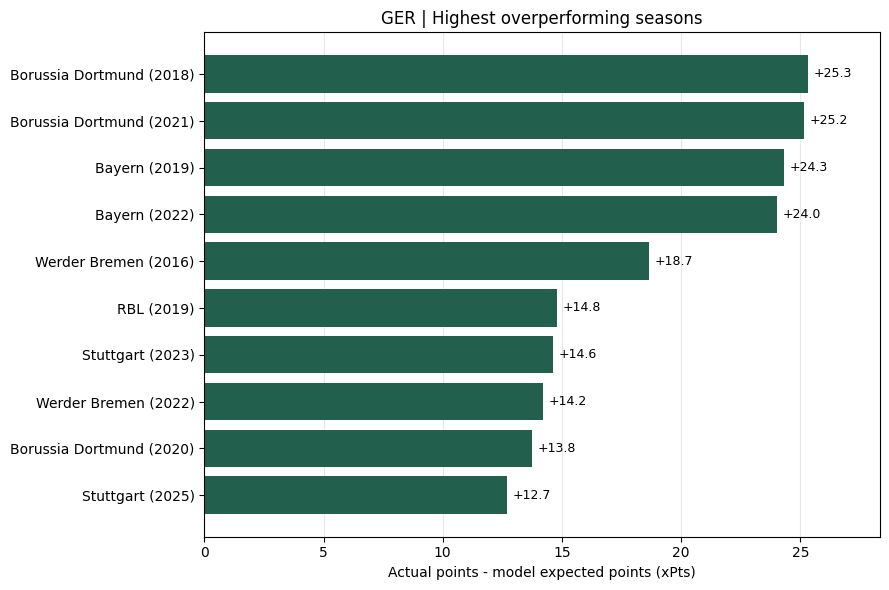

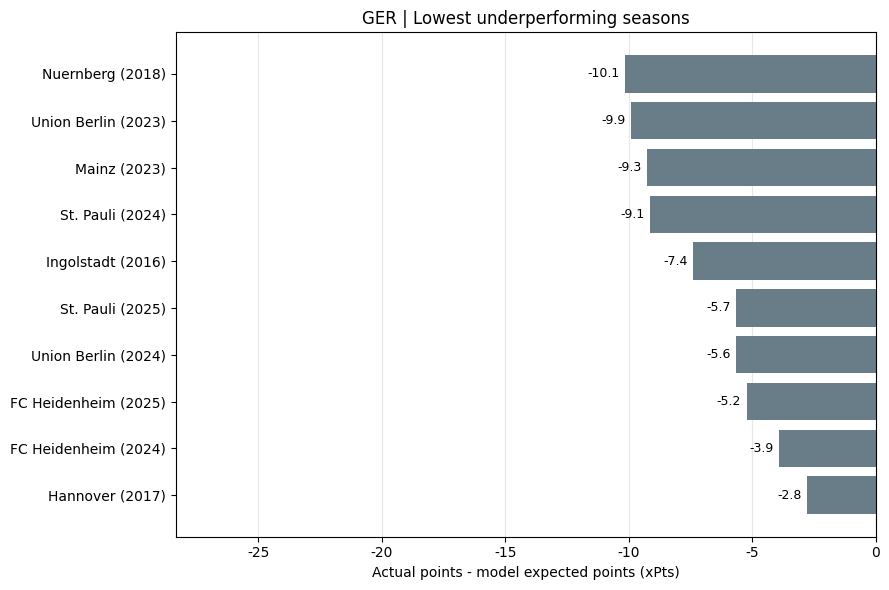

In [97]:
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

season_table = seasonTable[seasonTable["matches"] >= 34].copy()
season_table["season_id"] = "20" + season_table["season"].astype(str).str[2:4]
season_table["label"] = season_table["team"] + " (" + season_table["season_id"] + ")"
season_table["abs_diff"] = season_table["gf_diff"].abs()

n = 10
over_color, under_color = "#22604d", "#697d88ff"

# Largest gains (goals above xG) and largest drops (goals below xG)
top_gains = season_table.nlargest(n, "gf_diff").sort_values("abs_diff")
top_drops = season_table.nsmallest(n, "gf_diff").sort_values("abs_diff")

# Shared axis range so the two charts are comparable
xmax = max(top_gains["abs_diff"].max(), top_drops["abs_diff"].max()) + 3

def draw_chart(data, color, title, xlabel, right_justified=False):
    fig, ax = plt.subplots(figsize=(9, 6))
    bars = ax.barh(data["label"], data["abs_diff"], color=color, zorder=2)
    for i, (bar_len, signed) in enumerate(zip(data["abs_diff"], data["gf_diff"])):
        ax.annotate(f"{signed:+.1f}", xy=(bar_len, i),
                    xytext=(-4 if right_justified else 4, 0), textcoords="offset points",
                    ha="right" if right_justified else "left", va="center", fontsize=9)

    if right_justified:
        ax.set_xlim(xmax, 0)
        ax.xaxis.set_major_formatter(lambda x, pos: f"{-x:g}" if x != 0 else "0")
    else:
        ax.set_xlim(0, xmax)        # zero on the left, bars grow rightward

    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.xaxis.set_major_locator(MultipleLocator(5))
    ax.grid(axis="x", alpha=0.3, zorder=0)
    plt.tight_layout()
    plt.show()

draw_chart(top_gains, over_color,
           f"GER | Highest overperforming seasons",
           "Actual points - model expected points (xPts)")

draw_chart(top_drops, under_color,
           f"GER | Lowest underperforming seasons",
           "Actual points - model expected points (xPts)", right_justified=True)